In [33]:
import yfinance as yf
import pandas as pd
import numpy as np
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [34]:
# Downloading Data
tickers = ['SPY', 'AAPL', 'META', 'PLTR', 'TSLA', 'LLOY.L', 'BP.L', '^FTSE']

raw = yf.download(tickers, start='2021-01-01', end='2024-12-31', auto_adjust=True)
prices = raw['Close']

# calculating log returns
log_returns = np.log(prices / prices.shift(1)).dropna()

print(log_returns.shape)
print(log_returns.head())

[*********************100%***********************]  8 of 8 completed

(937, 8)
Ticker          AAPL      BP.L    LLOY.L      META      PLTR       SPY  \
Date                                                                     
2021-01-05  0.012288  0.068338  0.010708  0.007520  0.051293  0.006864   
2021-01-06 -0.034241  0.061552  0.053903 -0.028676 -0.044045  0.005960   
2021-01-07  0.033554  0.017784 -0.007292  0.020412  0.060175  0.014748   
2021-01-08  0.008594  0.012464 -0.001764 -0.004363  0.007968  0.005682   
2021-01-11 -0.023523  0.000335 -0.018085 -0.040928  0.028557 -0.006764   

Ticker          TSLA     ^FTSE  
Date                            
2021-01-05  0.007291  0.006129  
2021-01-06  0.027995  0.034134  
2021-01-07  0.076448  0.002205  
2021-01-08  0.075481  0.002374  
2021-01-11 -0.081442 -0.010942  


In [35]:
# Calculating Excess Returns
rf_annual = 0.045
rf_daily = rf_annual / 252

market_excess = log_returns['SPY'] - rf_daily

# filtering for stocks only
stocks = ['AAPL', 'META', 'PLTR', 'TSLA', 'LLOY.L', 'BP.L']
stock_excess = log_returns[stocks] - rf_daily

print ("Market excess returns (first 5):")
print (market_excess.head())
print ("\nStock excess returns (first 5):")
print (stock_excess.head())

Market excess returns (first 5):
Date
2021-01-05    0.006685
2021-01-06    0.005782
2021-01-07    0.014570
2021-01-08    0.005503
2021-01-11   -0.006942
Name: SPY, dtype: float64

Stock excess returns (first 5):
Ticker          AAPL      META      PLTR      TSLA    LLOY.L      BP.L
Date                                                                  
2021-01-05  0.012109  0.007341  0.051115  0.007112  0.010529  0.068159
2021-01-06 -0.034420 -0.028855 -0.044224  0.027816  0.053724  0.061374
2021-01-07  0.033376  0.020233  0.059996  0.076270 -0.007471  0.017606
2021-01-08  0.008416 -0.004541  0.007790  0.075303 -0.001942  0.012286
2021-01-11 -0.023702 -0.041107  0.028378 -0.081621 -0.018264  0.000156


In [36]:
# Finding Beta, Alpha, and R^2
results = {}

for ticker in stocks:
    y = stock_excess[ticker].dropna()
    x = market_excess[y.index]

    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

    results[ticker] = {
        'Beta': round(slope,4),
        'Alpha (ann.)': round(intercept * 252, 4),
        'R^2': round(r_value**2, 4)
    }

results_df = pd.DataFrame(results).T
print(results_df)

          Beta  Alpha (ann.)     R^2
AAPL    1.2189        0.0358  0.5803
META    1.6692       -0.0707  0.3644
PLTR    1.9878        0.0851  0.2504
TSLA    1.9297       -0.1466  0.2894
LLOY.L  0.3883       -0.0105  0.0574
BP.L    0.1748        0.0334  0.0107


In [37]:
# CAPM Expected Return
rf_annual = 0.045
market_return_annual = market_excess.mean() * 252 + rf_annual
equity_risk_premium = market_return_annual - rf_annual

capm_expected = {}

for ticker in stocks:
    beta = results[ticker]['Beta']
    capm_expected[ticker] = round(rf_annual + beta * equity_risk_premium, 4)

print(f"Equity Risk Premium (ERP) {equity_risk_premium:.4f}")
print(f"Market Return (ann. ): {market_return_annual:.4f}")
print()
print("CAPM Expected Returns:")
for ticker, exp_ret in capm_expected.items():
    print(f" {ticker:<8} {exp_ret:.4f}")

Equity Risk Premium (ERP) 0.1109
Market Return (ann. ): 0.1559

CAPM Expected Returns:
 AAPL     0.1802
 META     0.2301
 PLTR     0.2655
 TSLA     0.2590
 LLOY.L   0.0881
 BP.L     0.0644


In [38]:
# Summary Table
actual_returns = (log_returns[stocks].mean() * 252).to_dict()

summary = []
for ticker in stocks:
    actual = actual_returns[ticker]
    expected = capm_expected[ticker]
    alpha = results[ticker]['Alpha (ann.)']
    beta = results[ticker]['Beta']
    r2 = results[ticker]['R^2']

    summary.append({
        'Ticker': ticker,
        'Actual Return': f"{actual:.2%}",
        'CAPM Expected': f"{expected:.2%}",
        'Alpha (ann.)': f"{alpha:.2%}",
        'Beta': beta,
        'R^2': r2

    })

summary_df = pd.DataFrame(summary).set_index('Ticker')
print(summary_df.to_string())

       Actual Return CAPM Expected Alpha (ann.)    Beta     R^2
Ticker                                                         
AAPL          21.60%        18.02%        3.58%  1.2189  0.5803
META          15.94%        23.01%       -7.07%  1.6692  0.3644
PLTR          35.05%        26.55%        8.51%  1.9878  0.2504
TSLA          11.24%        25.90%      -14.66%  1.9297  0.2894
LLOY.L         7.76%         8.81%       -1.05%  0.3883  0.0574
BP.L           9.78%         6.44%        3.34%  0.1748  0.0107


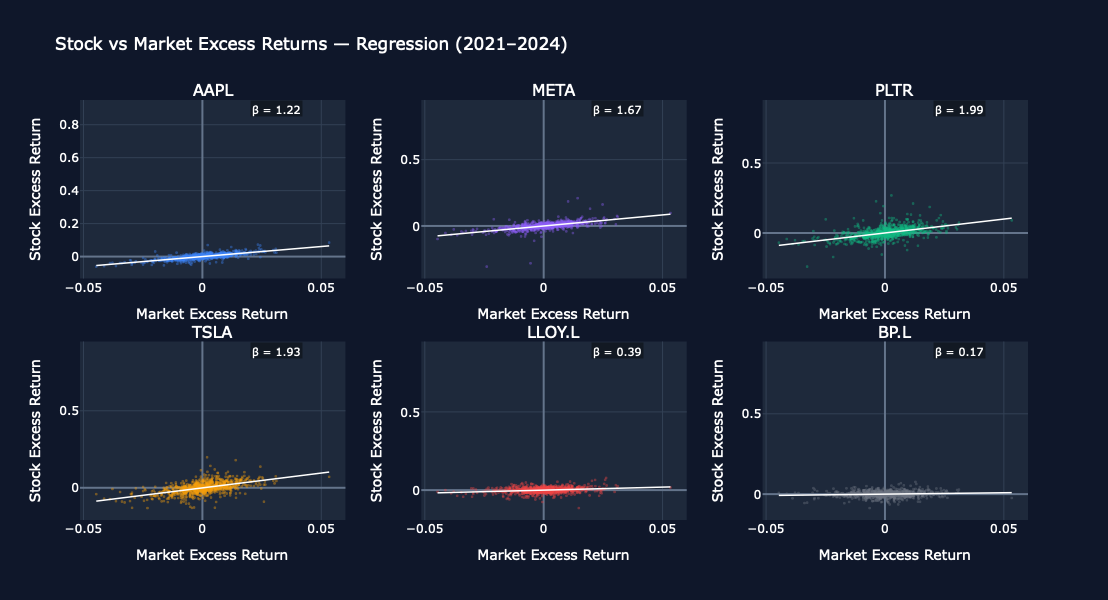

In [39]:
# Regression Subplots
fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=stocks,
    horizontal_spacing=0.08,
    vertical_spacing=0.15
)

colors = {
    'AAPL': '#3B82F6', 'META': '#8B5CF6', 'PLTR': '#10B981',
    'TSLA': '#F59E0B', 'LLOY.L': '#EF4444', 'BP.L': '#6B7280'
}

positions = [(1,1),(1,2),(1,3),(2,1),(2,2),(2,3)]

for i, ticker in enumerate(stocks):
    row, col = positions[i]
    x = market_excess.values
    y = stock_excess[ticker].values
    beta = results[ticker]['Beta']
    alpha_daily = results[ticker]['Alpha (ann.)'] / 252

    fig.add_trace(go.Scatter(
        x=x, y=y, mode='markers',
        marker=dict(color=colors[ticker], size=3, opacity=0.4),
        name=ticker, showlegend=False
    ), row=row, col=col)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = alpha_daily + beta * x_line
    fig.add_trace(go.Scatter(
        x=x_line, y=y_line, mode='lines',
        line=dict(color='white', width=1.5),
        showlegend=False
    ), row=row, col=col)

    fig.add_annotation(
        text=f"β = {beta:.2f}",
        xref=f"x{i+1}", yref=f"y{i+1}",
        x=0.02, y=0.95, xanchor='left', yanchor='top',
        showarrow=False,
        font=dict(color='white', size=11),
        bgcolor='rgba(0,0,0,0.4)'
    )

fig.update_layout(
    title='Stock vs Market Excess Returns — Regression (2021–2024)',
    paper_bgcolor='#0f172a',
    plot_bgcolor='#1e293b',
    font=dict(color='white'),
    height=600
)
fig.update_xaxes(showgrid=True, gridcolor='#334155', zeroline=True, zerolinecolor='#64748b', title_text='Market Excess Return')
fig.update_yaxes(showgrid=True, gridcolor='#334155', zeroline=True, zerolinecolor='#64748b', title_text='Stock Excess Return')

fig.show()

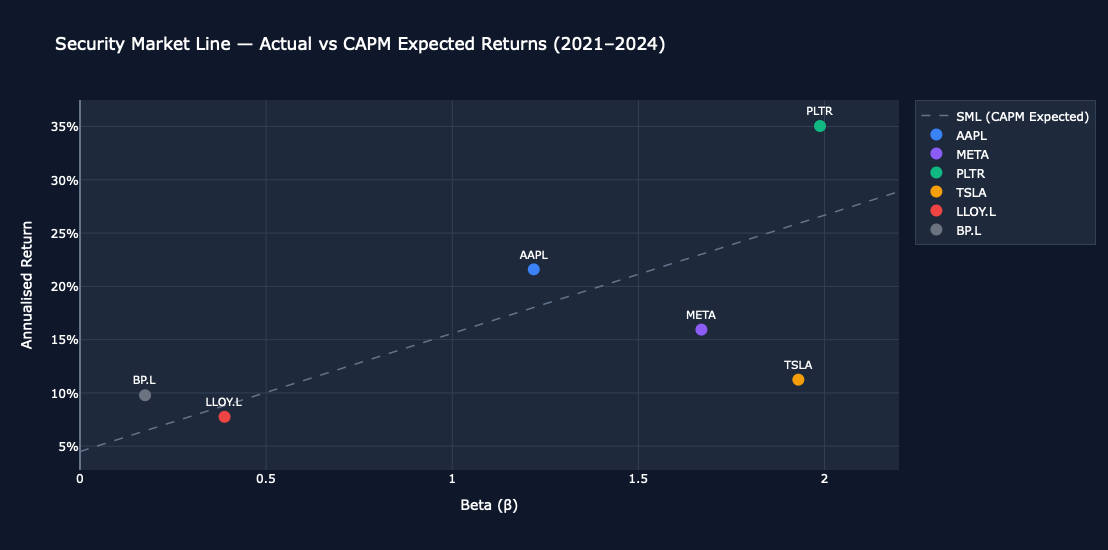

In [40]:
# Security Market Line (SML)
betas = [results[t]['Beta'] for t in stocks]
actual = [log_returns[t].mean() * 252 for t in stocks]
expected = [capm_expected[t] for t in stocks]

# SML line
beta_range = np.linspace(0, 2.2, 100)
sml_returns = rf_annual + beta_range * equity_risk_premium

fig2 = go.Figure()

# SML line
fig2.add_trace(go.Scatter(
    x=beta_range, y=sml_returns,
    mode='lines',
    line=dict(color='#64748b', width=1.5, dash='dash'),
    name='SML (CAPM Expected)'
))

# Stock dots
colors_list = ['#3B82F6','#8B5CF6','#10B981','#F59E0B','#EF4444','#6B7280']

for i, ticker in enumerate(stocks):
    fig2.add_trace(go.Scatter(
        x=[betas[i]], y=[actual[i]],
        mode='markers+text',
        marker=dict(color=colors_list[i], size=12),
        text=[ticker],
        textposition='top center',
        textfont=dict(color='white', size=11),
        name=ticker,
        showlegend=True
    ))

fig2.update_layout(
    title='Security Market Line — Actual vs CAPM Expected Returns (2021–2024)',
    xaxis_title='Beta (β)',
    yaxis_title='Annualised Return',
    paper_bgcolor='#0f172a',
    plot_bgcolor='#1e293b',
    font=dict(color='white'),
    legend=dict(bgcolor='#1e293b', bordercolor='#334155', borderwidth=1),
    height=550
)
fig2.update_xaxes(showgrid=True, gridcolor='#334155', zeroline=True, zerolinecolor='#64748b')
fig2.update_yaxes(showgrid=True, gridcolor='#334155', zeroline=True, zerolinecolor='#64748b', tickformat='.0%')

fig2.show()

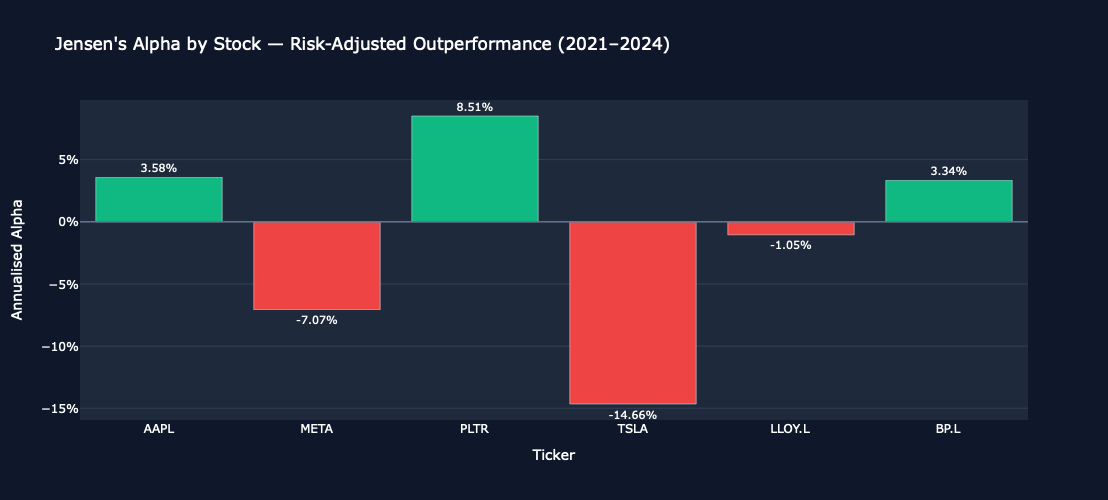

In [41]:
# Alpha Bar Chart
tickers_list = list(results.keys())
alphas = [results[t]['Alpha (ann.)'] for t in tickers_list]
bar_colors = ['#10B981' if a > 0 else '#EF4444' for a in alphas]

fig3 = go.Figure()

fig3.add_trace(go.Bar(
    x=tickers_list,
    y=alphas,
    marker_color=bar_colors,
    text=[f"{a:.2%}" for a in alphas],
    textposition='outside',
    textfont=dict(color='white', size=11)
))

fig3.add_hline(y=0, line_color='#64748b', line_width=1.5)

fig3.update_layout(
    title='Jensen\'s Alpha by Stock — Risk-Adjusted Outperformance (2021–2024)',
    xaxis_title='Ticker',
    yaxis_title='Annualised Alpha',
    paper_bgcolor='#0f172a',
    plot_bgcolor='#1e293b',
    font=dict(color='white'),
    height=500
)
fig3.update_xaxes(showgrid=False)
fig3.update_yaxes(showgrid=True, gridcolor='#334155', zeroline=False, tickformat='.0%')

fig3.show()